<center><h1>Disi_Sinan_HW6</h1></center>
<br>
<br>

Name: Sinan Disi
<br>
Github Username: Sinan-Disi
<br>
USC ID: 8053361335

## 1. Tree-Based Methods

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import confusion_matrix, accuracy_score, roc_curve, roc_auc_score
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

### (a) Download the APS Failure data

In [2]:
train = pd.read_csv("../data/aps_failure_training_set.csv", skiprows=20, na_values="na")
test = pd.read_csv("../data/aps_failure_test_set.csv", skiprows=20, na_values="na")
print("Training:", train.shape)
print("Testing:", test.shape)

Training: (60000, 171)
Testing: (16000, 171)


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Missing values can be handled by removing rows or filling them using the mean, median, mode, or methods like KNN imputation.

I chose median imputation because this dataset has many missing values, and the median is less affected by extreme values.

In [3]:
X_train = train.drop(columns="class")
X_test = test.drop(columns="class")

y_train = (train["class"] == "pos").astype(int)
y_test = (test["class"] == "pos").astype(int)

train_imputer = SimpleImputer(strategy="median")
test_imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(train_imputer.fit_transform(X_train), columns=X_train.columns)
X_test = pd.DataFrame(test_imputer.fit_transform(X_test), columns=X_test.columns)

print("Training missing values:", X_train.isna().sum().sum())
print("Testing missing values:", X_test.isna().sum().sum())

Training missing values: 0
Testing missing values: 0


#### (ii) Calculate the coefficient of variation

I calculated the coefficient of variation (CV) for all 170 features. CV is the standard deviation divided by the mean. A higher CV means more variation relative to the mean.

In [4]:
cv = (X_train.std() / X_train.mean()).sort_values(ascending=False)

print("Number of features:", len(cv))
display(cv.head(13).round(3))

Number of features: 170


cf_000    244.888
co_000    244.507
ad_000    244.323
cs_009    237.931
dh_000    123.216
dj_000    117.494
ag_000     92.918
as_000     87.332
ay_009     84.734
ak_000     80.425
az_009     77.839
ch_000     77.454
au_000     68.883
dtype: float64

#### (iii) Plot a correlation matrix

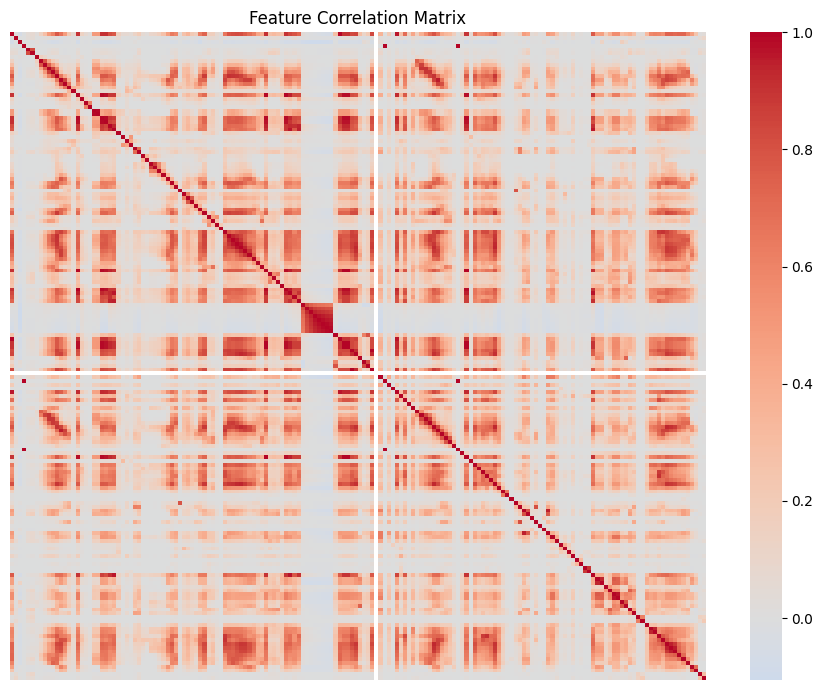

In [5]:
plt.figure(figsize=(9, 7))
sns.heatmap(X_train.corr(), cmap="coolwarm", center=0,
            xticklabels=False, yticklabels=False)
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

Some features are strongly positively correlated, while others have weak correlations. The white stripe comes from a constant feature, whose correlation is undefined.

#### (iv) Make scatter plots and box plots

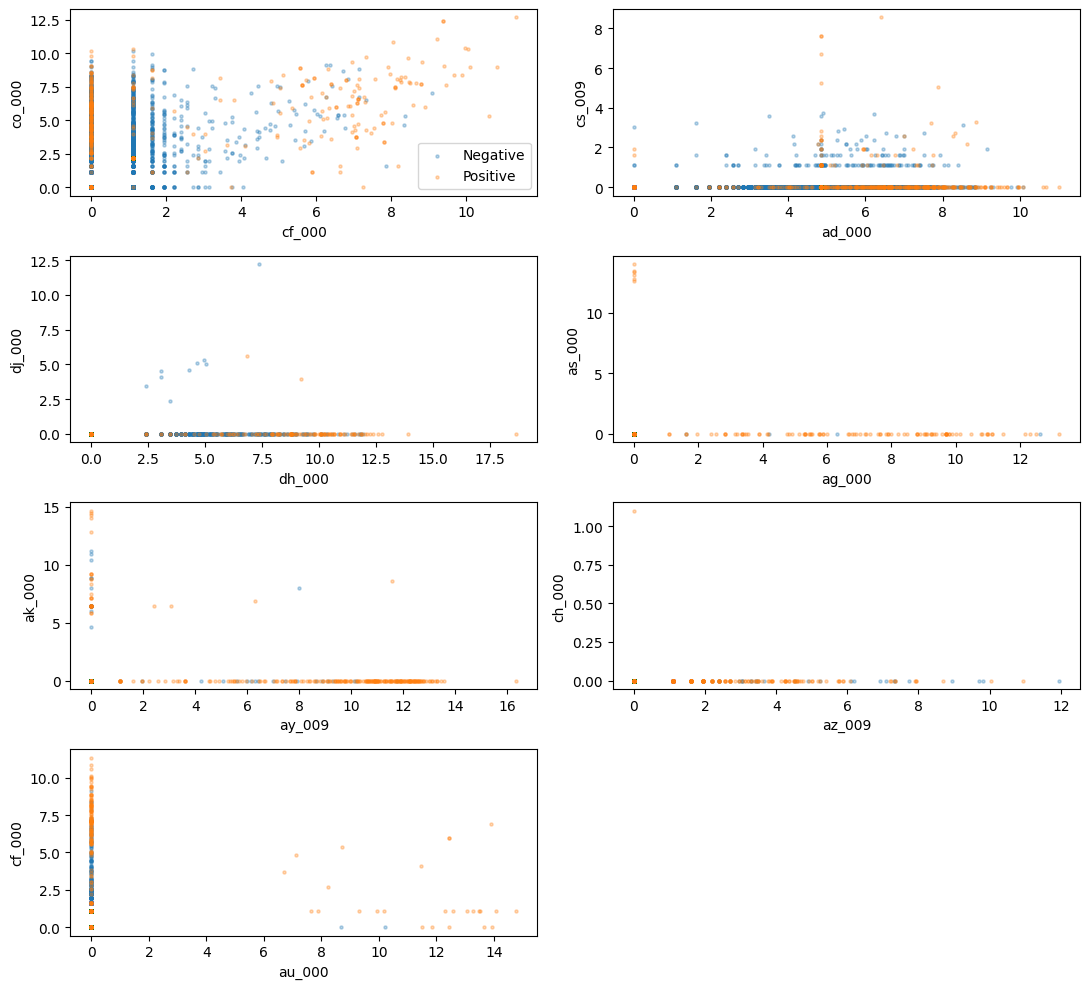

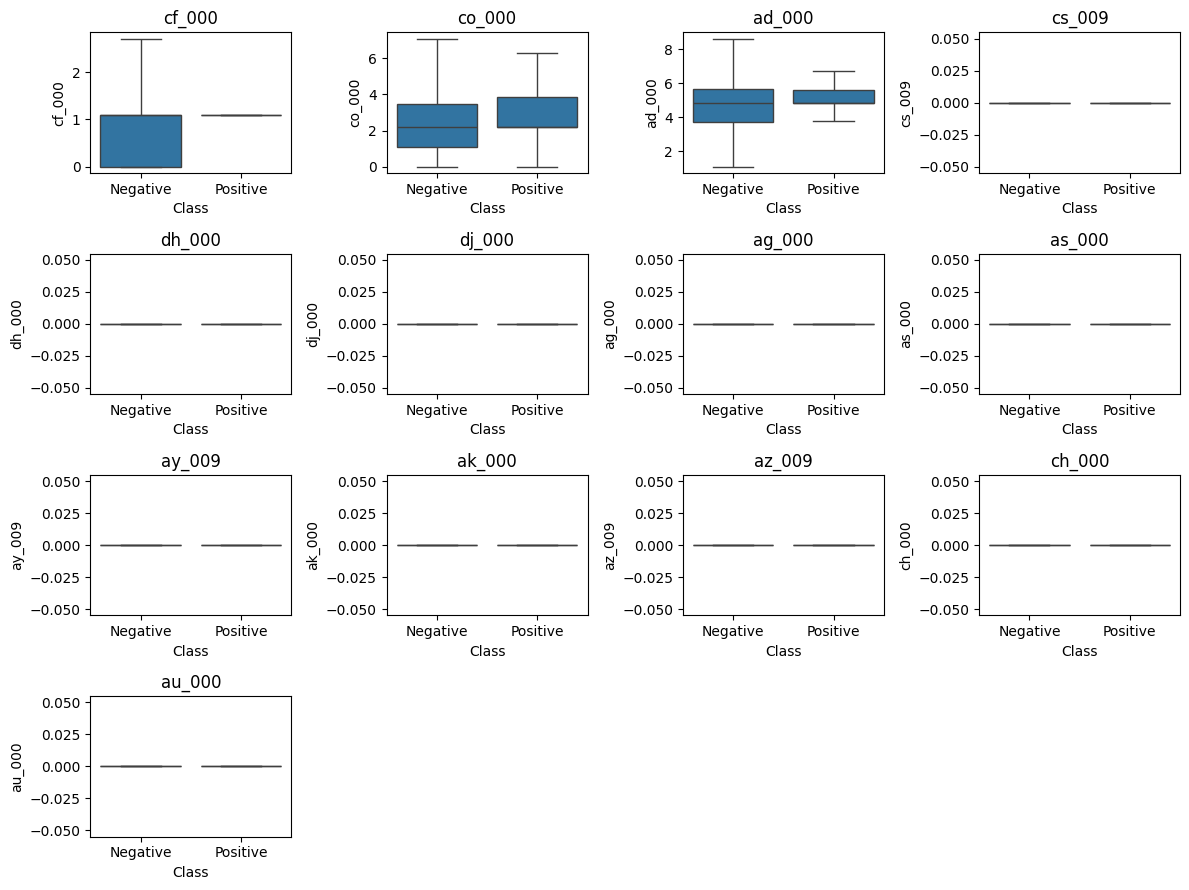

In [6]:
top13 = cv.head(13).index.tolist()

idx = pd.concat([
    y_train[y_train == 0].sample(3000, random_state=42),
    y_train[y_train == 1]]).index

# Scatter plots
scatter_df = np.log1p(X_train.loc[idx, top13].clip(lower=0))
positive = y_train.loc[idx] == 1

fig, axes = plt.subplots(4, 2, figsize=(11, 10))

for ax, i in zip(axes.flat, range(0, 13, 2)):
    a, b = top13[i], top13[(i + 1) % 13]

    ax.scatter(scatter_df.loc[~positive, a],
               scatter_df.loc[~positive, b],
               s=5, alpha=0.3, label="Negative")

    ax.scatter(scatter_df.loc[positive, a],
               scatter_df.loc[positive, b],
               s=5, alpha=0.3, label="Positive")
    ax.set_xlabel(a)
    ax.set_ylabel(b)

axes.flat[0].legend()
axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()

# Box plots
plot_df = np.log1p(X_train[top13].clip(lower=0))
plot_df["Class"] = y_train.map({0: "Negative", 1: "Positive"})

fig, axes = plt.subplots(4, 4, figsize=(12, 9))

for ax, feature in zip(axes.flat, top13):
    sns.boxplot(data=plot_df, x="Class", y=feature,
                showfliers=False, ax=ax)
    ax.set_title(feature)

for ax in axes.flat[13:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

I used log(1+x) to make the feature values easier to compare. For the scatter plots, I selected 3,000 negative observations and all 1,000 positive observations. I also hid the extreme outliers in the box plots for readability. These changes were only for visualization, and the models still use the full dataset.
Some features show differences between the positive and negative classes. However, scatter plots alone are not enough to determine which features are significant. We need further analysis to confirm their importance.

#### (v) Is this data set imbalanced?

In [7]:
print("Training:")
print(train["class"].value_counts())

print("\nTesting:")
print(test["class"].value_counts())

print("\nTraining positive percentage:", round(y_train.mean() * 100, 2), "%")

Training:
class
neg    59000
pos     1000
Name: count, dtype: int64

Testing:
class
neg    15625
pos      375
Name: count, dtype: int64

Training positive percentage: 1.67 %


Yes, the dataset is highly imbalanced. Only 1.67% of the training observations belong to the positive class, while 98.33% belong to the negative class.

### (c) Train a random forest

OOB Error: 0.0058
Training Confusion Matrix:
[[59000     0]
 [    1   999]]
Training Error: 0.0000
Training AUC: 1.0000

Testing Confusion Matrix:
[[15610    15]
 [  105   270]]
Testing Error: 0.0075
Testing AUC: 0.9943



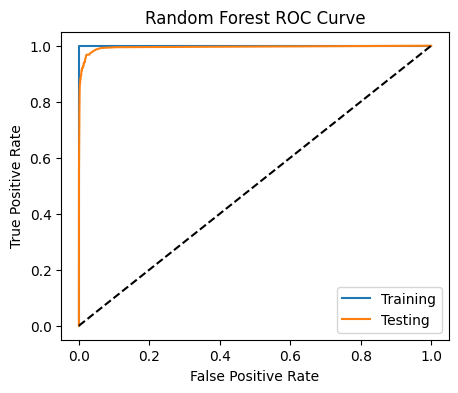

In [8]:
rf = RandomForestClassifier(
    n_estimators=150,
    oob_score=True,
    random_state=42,
    n_jobs=-1)
rf.fit(X_train, y_train)

print("OOB Error:", round(1 - rf.oob_score_, 4))

def evaluate_model(model, name):
    plt.figure(figsize=(5, 4))

    for label, X, y in [("Training", X_train, y_train),
                        ("Testing", X_test, y_test)]:
        pred = model.predict(X)
        prob = model.predict_proba(X)[:, 1]

        print(f"{label} Confusion Matrix:\n{confusion_matrix(y, pred)}")
        print(f"{label} Error: {1 - accuracy_score(y, pred):.4f}")
        print(f"{label} AUC: {roc_auc_score(y, prob):.4f}\n")

        fpr, tpr, _ = roc_curve(y, prob)
        plt.plot(fpr, tpr, label=f"{label}")

    plt.plot([0, 1], [0, 1], "k--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{name} ROC Curve")
    plt.legend()
    plt.show()

evaluate_model(rf, "Random Forest")

The random forest has almost zero training error and a test error of 0.75%, with a test AUC of 0.9943. The OOB error is 0.58%, which is close to the test error but slightly lower. However, the model missed 105 out of 375 positive test cases, showing that class imbalance is still a concern.

### (d) Research class imbalance in random forest

Class imbalance in random forests can be handled using class weights or resampling. I used balanced_subsample, which gives more weight to the minority class when training each tree. This helps the model pay more attention to positive cases.

Balanced RF OOB Error: 0.0079
Training Confusion Matrix:
[[59000     0]
 [    1   999]]
Training Error: 0.0000
Training AUC: 1.0000

Testing Confusion Matrix:
[[15611    14]
 [  158   217]]
Testing Error: 0.0108
Testing AUC: 0.9920



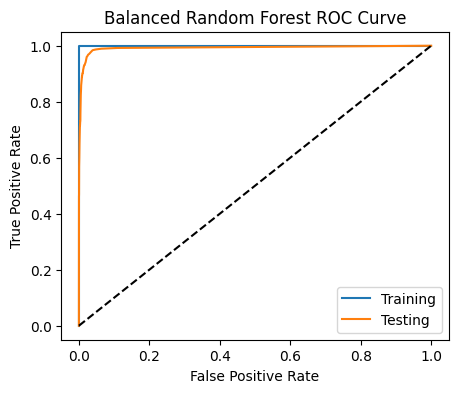

In [9]:
rf_bal = RandomForestClassifier(
    n_estimators=150,
    class_weight="balanced_subsample",
    oob_score=True,
    random_state=42,
    n_jobs=-1)
rf_bal.fit(X_train, y_train)

print("Balanced RF OOB Error:", round(1 - rf_bal.oob_score_, 4))

evaluate_model(rf_bal, "Balanced Random Forest")

Compared with the original random forest, the balanced model had a higher test error (1.08% vs. 0.75%) and a slightly lower AUC (0.9920 vs. 0.9943). The OOB error also increased from 0.58% to 0.79%. It missed more positive test cases (158 vs. 105). Therefore, class weighting did not improve performance in this case.

### (e) XGBoost and Model Trees

In [10]:
xgb_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("xgb", XGBClassifier(
        objective="binary:logistic",
        booster="gbtree",
        n_estimators=180,
        max_depth=4,
        learning_rate=0.1,
        subsample=0.9,
        colsample_bytree=0.9,
        tree_method="hist",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1))])

xgb_cv = GridSearchCV(
    xgb_pipe,
    {"xgb__reg_alpha": [0, 0.01, 0.1, 1, 10]},
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    scoring={"AUC": "roc_auc", "Accuracy": "accuracy"},
    refit="AUC",
    n_jobs=1)

xgb_cv.fit(train.drop(columns="class"), y_train)

print("Best alpha:", xgb_cv.best_params_["xgb__reg_alpha"])
print("5-fold CV Error:",
      round(1 - xgb_cv.cv_results_["mean_test_Accuracy"][xgb_cv.best_index_], 4))

Best alpha: 1
5-fold CV Error: 0.0058


Training Confusion Matrix:
[[58993     7]
 [   72   928]]
Training Error: 0.0013
Training AUC: 0.9995

Testing Confusion Matrix:
[[15608    17]
 [   93   282]]
Testing Error: 0.0069
Testing AUC: 0.9962



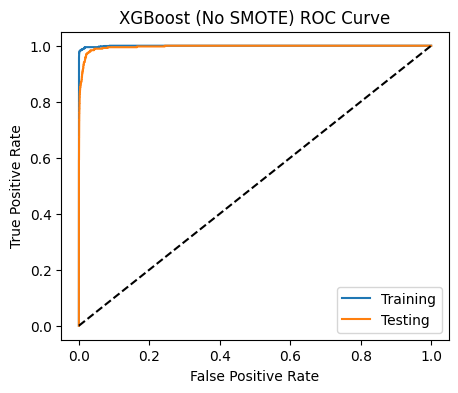

In [11]:
evaluate_model(xgb_cv.best_estimator_, "XGBoost (No SMOTE)")

I used XGBoost with a binary logistic objective and L1 regularization. I selected the regularization parameter α based on the highest average AUC from stratified 5-fold cross-validation. No class balancing was applied.

### (f) Use SMOTE to pre-process your data

In [12]:
smote_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("smote", SMOTE(random_state=42)),
    ("xgb", xgb_pipe.named_steps["xgb"])])

smote_cv = GridSearchCV(
    smote_pipe,
    {"xgb__reg_alpha": [0, 0.01, 0.1, 1, 10]},
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    scoring={"AUC": "roc_auc", "Accuracy": "accuracy"},
    refit="AUC",
    n_jobs=1)
smote_cv.fit(train.drop(columns="class"), y_train)

print("Best alpha:", smote_cv.best_params_["xgb__reg_alpha"])
print("5-fold CV Error:",
      round(1 - smote_cv.cv_results_["mean_test_Accuracy"][smote_cv.best_index_], 4))

Best alpha: 1
5-fold CV Error: 0.0098


Training Confusion Matrix:
[[58716   284]
 [   55   945]]
Training Error: 0.0057
Training AUC: 0.9986

Testing Confusion Matrix:
[[15446   179]
 [   42   333]]
Testing Error: 0.0138
Testing AUC: 0.9939



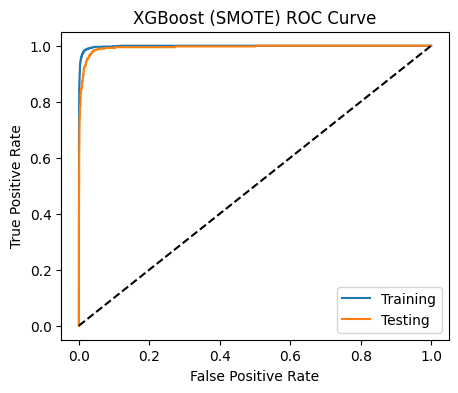

In [13]:
evaluate_model(smote_cv.best_estimator_, "XGBoost (SMOTE)")

SMOTE creates synthetic examples of the minority class to reduce class imbalance. I applied SMOTE inside the cross-validation pipeline so that only the training folds are balanced. The validation and test data remain unchanged.

I selected alpha using the highest average AUC from 5-fold cross-validation and reported the corresponding classification error.

However, SMOTE detected more positive cases (333 vs. 282) and missed fewer (42 vs. 93). It also produced more false positives (179 vs. 17). Therefore, SMOTE improved the detection of positive cases but increased the overall error.

## 2. ISLR 6.6.3

As s increases, the Lasso constraint becomes less strict, allowing the model to be more flexible.

(a) iv. Steadily decrease.
As the model becomes more flexible, it can fit the training data better, so training RSS cannot increase.

(b) ii. Decrease initially, then increase.
Test RSS typically decreases at first as the model improves, but eventually increases due to overfitting.

(c) iii. Steadily increase.
A more flexible model is more sensitive to changes in the training data, increasing variance.

(d) iv. Steadily decrease.
As the constraint becomes less strict, the model can better capture the true relationship, reducing squared bias.

(e) v. Remain constant.
Irreducible error comes from random noise in the data and does not change with model flexibility.

## 3. ISLR 6.6.5

Given the conditions, let $x_{11}=x_{12}=x$, $x_{21}=x_{22}=-x$, $y_1=y$, and $y_2=-y$.

**(a) Ridge Regression**

The optimization problem is:

$$
\min_{\beta_1,\beta_2}
2(y-x(\beta_1+\beta_2))^2+\lambda(\beta_1^2+\beta_2^2)
$$

**(b) Equal Ridge Coefficients**

Since the predictors are identical, predictions depend only on the sum of their coefficients.

Also,

$$
\beta_1^2+\beta_2^2=
\frac{(\beta_1+\beta_2)^2+(\beta_1-\beta_2)^2}{2}
$$

For a fixed sum and $\lambda>0$, the Ridge penalty is smallest when $\beta_1-\beta_2=0$.

Therefore,

$$
\hat{\beta}_1=\hat{\beta}_2
$$

**(c) Lasso Regression**

The optimization problem is:

$$
\min_{\beta_1,\beta_2}
2(y-x(\beta_1+\beta_2))^2+\lambda(|\beta_1|+|\beta_2|)
$$

**(d) Multiple Lasso Solutions**

Since the predictors are identical, only the sum of their coefficients matters.

If the optimal sum is $s^* \neq 0$, all coefficient pairs

$$
(\hat{\beta}_1,\hat{\beta}_2)=(ts^*,(1-t)s^*), \quad 0 \leq t \leq 1
$$

give the same predictions and Lasso penalty.

For example, when $s^*=2$, the pairs $(2,0)$, $(1,1)$, and $(0,2)$ are all optimal.

If the optimal sum is zero and $\lambda>0$, the only Lasso solution is $(0,0)$.

## 4. ISLR 8.4.5

**Majority Vote**

Six trees predict Red (probability above 0.5), while four predict Green. Therefore, the final prediction is Red.

**Average Probability**

The average probability of Red is:

$$
\frac{4.50}{10}=0.45
$$

Since 0.45 is below 0.5, the final prediction is Green.

## 5. ISLR 9.7.3

**(a)** The seven observations are plotted below, with four Red and three Blue points.

**(b)** The maximal-margin separating line is $X_2=X_1-0.5$. It separates the two classes with the largest possible margin.

**(c)** An observation is classified as Red if $0.5-X_1+X_2>0$, and Blue otherwise.

Therefore, $\beta_0=0.5$, $\beta_1=-1$, and $\beta_2=1$.

**(d)** The two dotted lines, $X_2=X_1$ and $X_2=X_1-1$, show the margin boundaries. The distance from the separating line to either boundary is:

$$
\text{Margin}=\frac{0.5}{\sqrt{2}}\approx 0.354
$$

**(e)** Observations 2 and 3 (Red) and 5 and 6 (Blue) are the support vectors. They are the closest points to the separating line and lie on the margin boundaries.

**(f)** Observation 7 is not a support vector, so moving it slightly does not affect the maximal-margin line.

**(g)** Another separating line is $X_2=X_1-0.25$. It separates the original observations, but its margin is smaller than the optimal one.

**(h)** I added a Red point at $(4,2)$, between the Blue points at $(4,1)$ and $(4,3)$. With this new point, the classes cannot be separated by a straight line.

The red X shows the added point for part (h). The separating lines are based on the original seven observations.

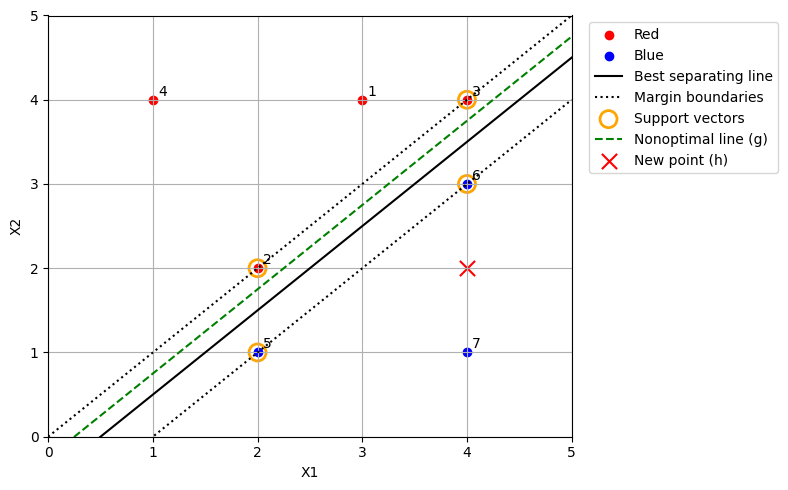

In [14]:
red = np.array([[3, 4], [2, 2], [4, 4], [1, 4]])
blue = np.array([[2, 1], [4, 3], [4, 1]])

plt.figure(figsize=(8, 5))
plt.scatter(red[:, 0], red[:, 1], color="red", label="Red")
plt.scatter(blue[:, 0], blue[:, 1], color="blue", label="Blue")

for i, (x, y) in enumerate(np.vstack((red, blue)), 1):
    plt.text(x + 0.05, y + 0.05, str(i))

plt.xlim(0, 5)
plt.ylim(0, 5)
plt.xlabel("X1")
plt.ylabel("X2")
x_line = np.linspace(0, 5, 100)
plt.plot(x_line, x_line - 0.5, "k-", label="Best separating line")
plt.plot(x_line, x_line, "k:", label="Margin boundaries")
plt.plot(x_line, x_line - 1, "k:")
plt.scatter([2, 4, 2, 4], [2, 4, 1, 3],
            s=150, facecolors="none", edgecolors="orange",
            linewidths=2, label="Support vectors")
plt.plot(x_line, x_line - 0.25, "g--", label="Nonoptimal line (g)")
plt.scatter(4, 2, color="red", marker="x", s=120, label="New point (h)")
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.grid(True)
plt.show()

### AI Assistance Disclosure and Prompts Used

I used AI mainly to help understand the assignment, clarify programming and statistical concepts, and get Python coding examples for data preprocessing, Random Forest, XGBoost, and SMOTE. I also used it to better understand the concepts in Section 5 (ISLR 9.7.3). I ran the final code and reviewed the answers before submission.

Prompts:

1) Can you show me a simple Python example of handling missing values using median imputation and calculating the coefficient of variation for different features?
2) Can you explain class imbalance and show me how to evaluate a Random Forest using OOB error, confusion matrices, and ROC/AUC?
3) Can you show me an example of using SMOTE with Random Forest and explain how to compare the results before and after balancing the classes?
4) Can you show me a Python example of training XGBoost and using cross-validation to select hyperparameters and compare test errors?
5) Can you explain the concepts behind ISLR 9.7.3 and provide a simple example to help me understand them?